### (29.1)Problem 1:

In [243]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hilbert
from matplotlib.ticker import MaxNLocator

In [244]:
# a)
def tridiag(A):
    T = A.astype(float).copy()
    m = T.shape[0]
    for k in range(m - 2):
        x = T[k + 1:, k].copy()
        v = x.copy()
        v[0] += np.copysign(np.linalg.norm(x), x[0])
        v /= np.linalg.norm(v)
        T[k + 1:, k:] -= 2 * np.outer(v, v @ T[k + 1:, k:])
        T[:, k + 1:] -= 2 * np.outer(T[:, k + 1:] @ v, v)
    return np.triu(np.tril(T, 1), -1)

A = hilbert(4)
print(tridiag(A))

[[ 1.00000000e+00 -6.50854140e-01  0.00000000e+00  0.00000000e+00]
 [-6.50854140e-01  6.50585480e-01  6.39118800e-02  0.00000000e+00]
 [ 0.00000000e+00  6.39118800e-02  2.53201434e-02 -1.16520804e-03]
 [ 0.00000000e+00  0.00000000e+00 -1.16520804e-03  2.84852680e-04]]


In [245]:
# b)
def qralg(T, shift=False):
    T = T.copy()
    m = T.shape[0]
    errs = []
    while abs(T[-1, -2]) >= 1e-12:
        mu = 0.0
        if shift:
            a, b, c = T[-2, -2], T[-1, -2], T[-1, -1]
            delta = (a - c) / 2
            mu = c - np.copysign(1.0, delta) * b**2 / (abs(delta) + np.hypot(delta, b))
        Q, R = np.linalg.qr(T - mu * np.eye(m))
        T = R @ Q + mu * np.eye(m)
        errs.append(abs(T[-1, -2]))
    return T, errs

Tnew, err = qralg(tridiag(A))
print(Tnew)
# print(len(err)) converges after 5 iterattions

[[ 1.50021428e+00 -1.78075254e-05  1.38084644e-16 -1.31668527e-17]
 [-1.78075254e-05  1.69141220e-01  5.62874387e-09 -1.34260049e-17]
 [ 0.00000000e+00  5.62874380e-09  6.73827361e-03  6.88691349e-13]
 [ 0.00000000e+00  0.00000000e+00  6.88691517e-13  9.67023040e-05]]


In [ ]:
# c)
def eigen_driver(A, shift=False):
    T = tridiag(A)
    eigs, errs = [], []
    while T.shape[0] > 1:
        T, e = qralg(T, shift)
        errs += e
        eigs.append(T[-1, -1])
        T = T[:-1, :-1]
    eigs.append(T[0, 0])
    plt.semilogy(errs, '.-')
    plt.xlabel("# of QR factorizations")
    plt.ylabel("$|t_{m,m-1}|$")
    plt.title(f"{'Wilkinson shift' if shift else 'Unshifted'}, m = {A.shape[0]}")
    plt.grid(alpha=0.3)
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()
    return np.array(eigs)

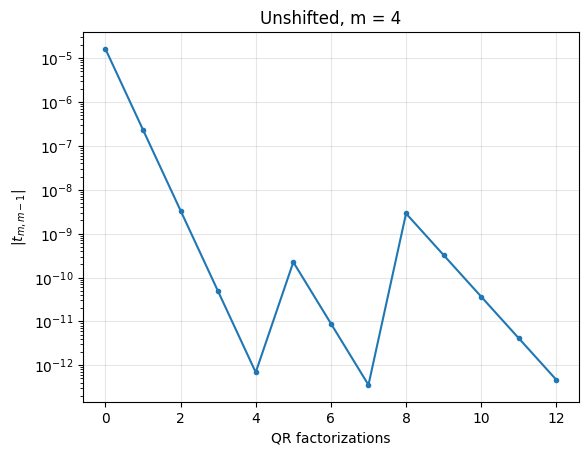

[9.67023040e-05 6.73827361e-03 1.69141220e-01 1.50021428e+00]


In [247]:
#No shift Saw tooth:
print(eigen_driver(hilbert(4)))

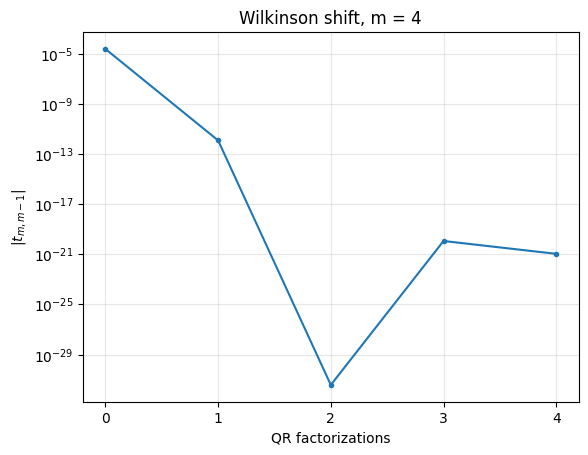

[9.67023040e-05 6.73827361e-03 1.69141220e-01 1.50021428e+00]


In [ ]:
# d) Wilkinson shift:
print(eigen_driver(hilbert(4), shift=True))

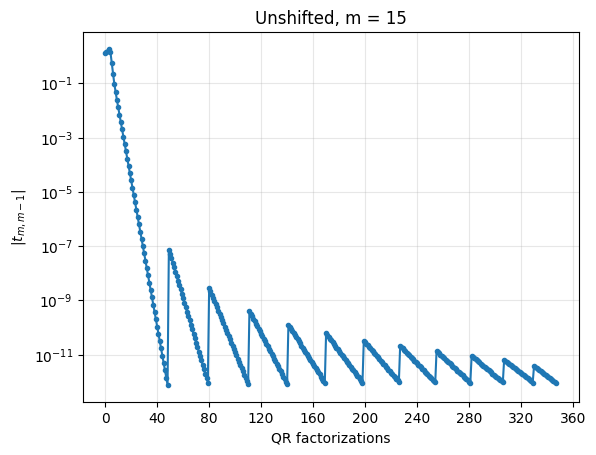

[ 1.21465537  2.25695098  3.28777559  4.31431185  5.33895988  6.36294449
  7.38709275  8.41211207  9.43874576 10.46792166 11.50098302 12.54018637
 13.59013196 14.664097   24.22313127]


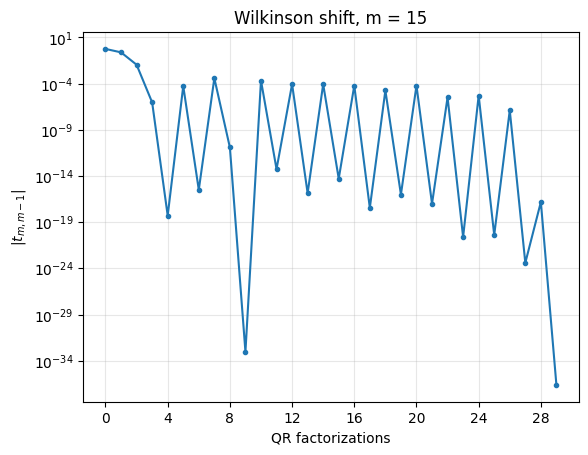

[ 8.41211207  9.43874576  7.38709275  6.36294449 10.46792166  5.33895988
 11.50098302  4.31431185  3.28777559 12.54018637  2.25695098 13.59013196
  1.21465537 14.664097   24.22313127]


In [249]:
# e)
B = np.diag(np.arange(15, 0, -1)) + np.ones((15, 15))
print(eigen_driver(B))
print(eigen_driver(B, shift=True))

**(e) Description:**

**Unshifted:**

The difference in convergence rates is more apparent in the larger matrices considered here. Crucially, at m = 15, we see that within each eigenvalue convergence cycle (i.e. one tooth on the graph), each iteration removes roughly the same fraction of the remaining off-diagonal magnitude. This produces a roughly constant downward slope on the logarithmic plot, showing linear convergence. Once the entry drops below the tolerance of $10^{-12}$, an eigenvalue is accepted and the next tooth begins.

**Wilkinson shift:**

Introducing a Wilkinson shift accelerates the decay of the off-diagonal entry by choosing a shift close to the eigenvalue being isolated. As convergence progresses, successive iterations can reduce the entry by increasingly large factors, bringing it below the tolerance in far fewer steps. A cubic convergence rate for Wilkinson shifts is consistent with these short, sharply descending teeth. As a result, the plotted results show substantially faster convergence than the unshifted computations.

---


### (30.7) Problem 2:

In [186]:
import numpy as np
import time
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed = 42)
OUT = "/Users/nhoojaroy/Desktop/Fall 2026/NumericalLinearAlg/Class-Projects/Homework_6/output"

**Set Up**

Since, we are not given a distribution to sample from, assume each entry for the random tridiagonal, symmetric matrix is sampled from a unifrom distribution.

 $$t_{ij} \sim Uniform[-3, 3]$$

In [121]:
def T(n):
    off_diag = rng.uniform(-3,3, size=n-1)
    on_diag = rng.uniform(-3,3, size=n)
    T = np.diag(on_diag)+ np.diag(off_diag, k=1) + np.diag(off_diag, k=-1)
    return T

def L(n):
    L = np.eye(n)*-2 + np.diag(np.ones(n-1), k= 1)+ np.diag(np.ones(n-1), k=-1)
    return L

In [250]:
def diagnostics(T):
    '''Prints diagnositic summary, and returns eigen decomp'''
    dim = T.shape[0]
    t0 = time.perf_counter()
    d, Q = np.linalg.eig(T)
    t = time.perf_counter()-t0
    D = np.diag(d)
    recon = Q @ D @ Q.T
    recon_err = np.linalg.norm((T- recon))
    ortho_err = np.linalg.norm(Q@Q.T - np.eye(Q.shape[0]))
    
    print('Diagonostic Summary:')
    print('---'*50)
    print("Reconstruction Error (‖T − QDQᵀ‖): ", recon_err)
    print("Orthogonality Error (‖I − QQᵀ‖): ", ortho_err)
    print("Number of elements ≥ 10⁻¹⁰: ", count_small(Q, 1e-10))
    print("Relative percentage of number of elements ≥ 10⁻¹⁰: ", (count_small(Q, 1e-10)/dim**2)*100)
    print(f'Runtime for m = {dim} matrix : {t} seconds')
    print('---'*50)
    print('End of Summary')
    return d, Q

def count_small(A, tol):
    return np.count_nonzero(np.abs(A) > tol)

def plot_log(d, Q, random: str):
    cols = [0, 14, 29, 44, 59, 74, 89, 99]
    n = Q.shape[1]
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
    for ax, j in zip(axes.flat, cols):
        k = (j + 5) % n
        ax.semilogy(np.abs(Q[:, j]), label=f"column {j+1}")
        ax.semilogy(np.abs(Q[:, k]), label=f"column {k+1}")
        ax.set_xlabel("component index i")
        ax.grid(alpha=0.4)
        ax.legend()
    axes[0, 0].set_ylabel(r"$|Q_{ij}|$")
    axes[1, 0].set_ylabel(r"$|Q_{ij}|$")
    fig.suptitle(f"Localization Pattern for {random} matrix")
    plt.tight_layout()
    plt.savefig(OUT+f"/Localization_{random}.png")
    plt.show()

Diagonostic Summary:
------------------------------------------------------------------------------------------------------------------------------------------------------
Reconstruction Error (‖T − QDQᵀ‖):  1.6708549380417955e-12
Orthogonality Error (‖I − QQᵀ‖):  4.648072599061818e-13
Number of elements ≥ 10⁻¹⁰:  5619
Relative percentage of number of elements ≥ 10⁻¹⁰:  56.19
Runtime for m = 100 matrix : 0.0283698751591146 seconds
------------------------------------------------------------------------------------------------------------------------------------------------------
End of Summary


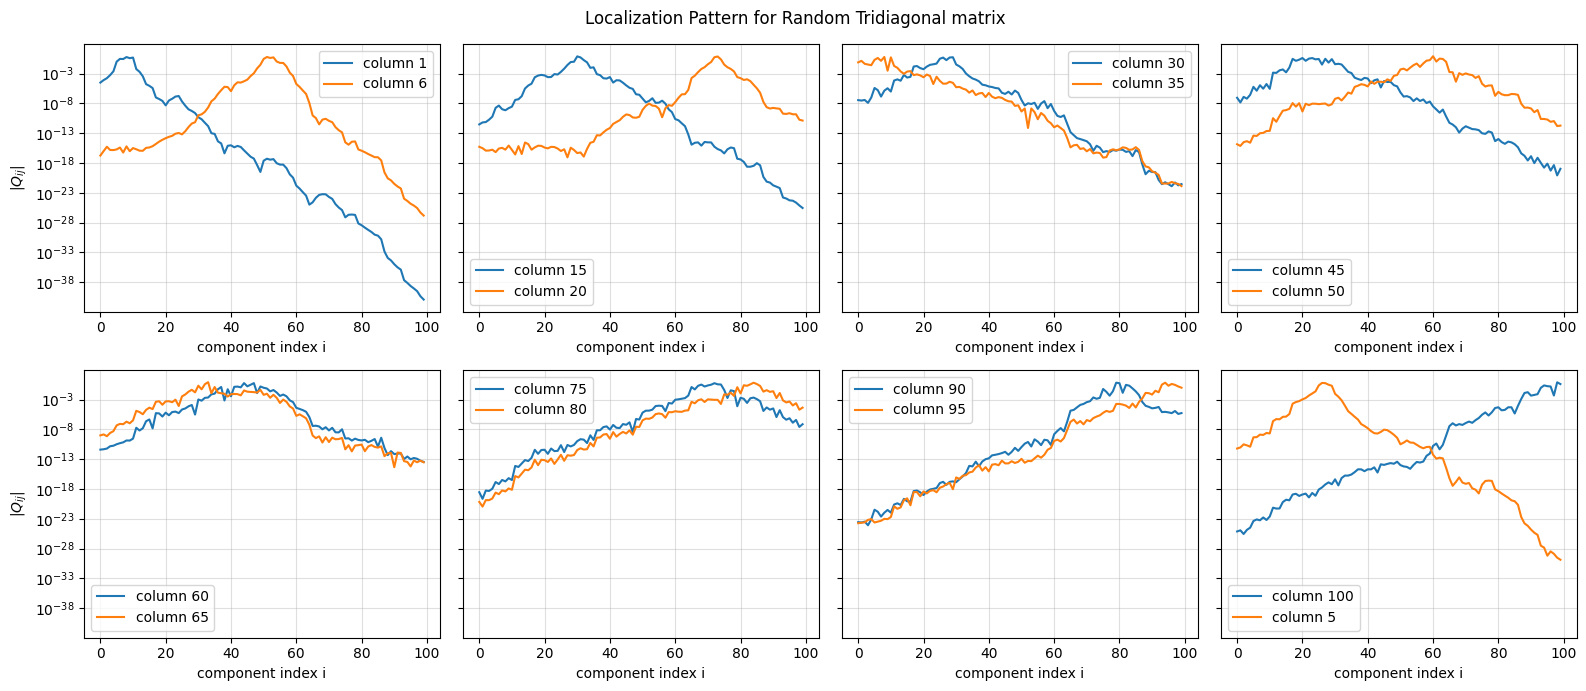

In [251]:
A = T(100)
d, Q = diagnostics(A)
plot_log(d, Q, 'Random Tridiagonal')

Diagonostic Summary:
------------------------------------------------------------------------------------------------------------------------------------------------------
Reconstruction Error (‖T − QDQᵀ‖):  8.266514492510401e-13
Orthogonality Error (‖I − QQᵀ‖):  3.0520956130984585e-13
Number of elements ≥ 10⁻¹⁰:  10000
Relative percentage of number of elements ≥ 10⁻¹⁰:  100.0
Runtime for m = 100 matrix : 0.014086166862398386 seconds
------------------------------------------------------------------------------------------------------------------------------------------------------
End of Summary


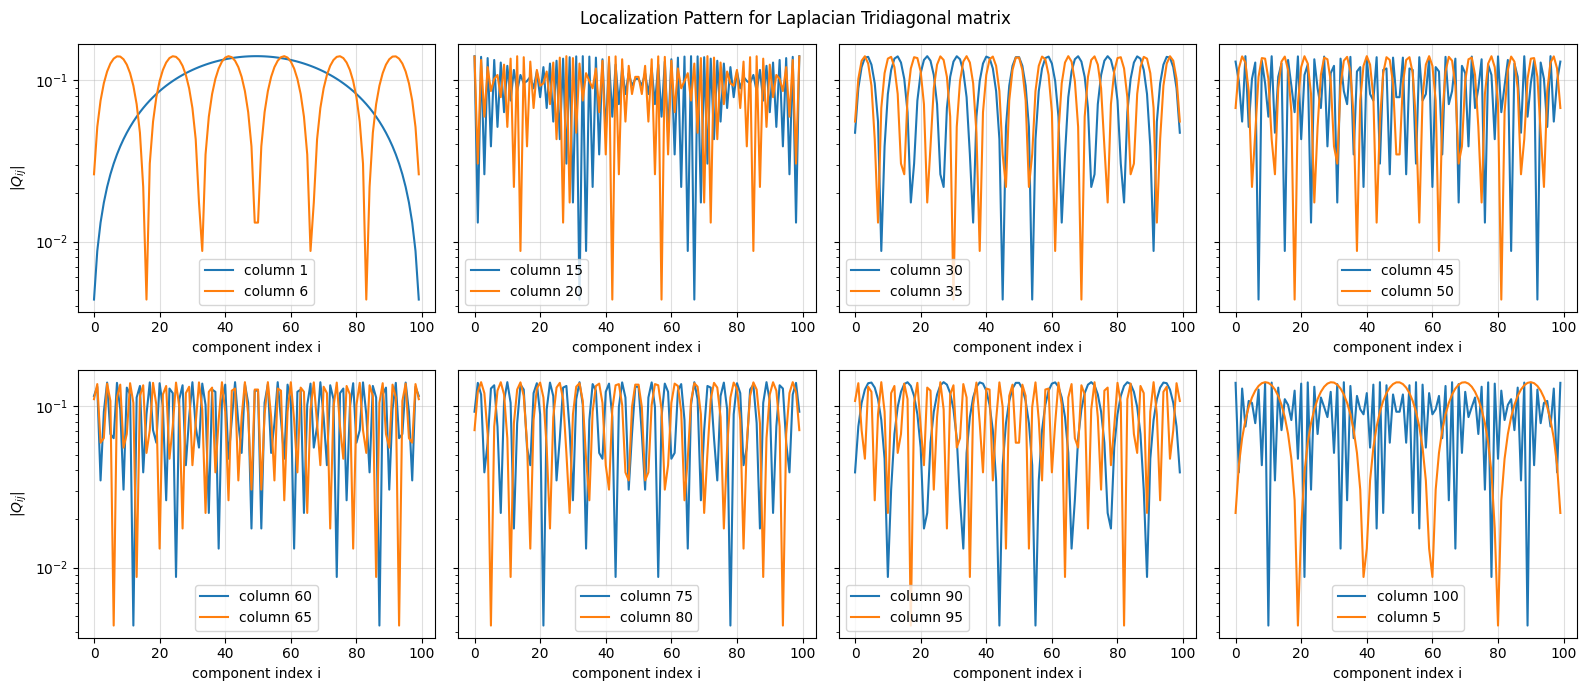

In [252]:
B = L(100)
d1, Q1= diagnostics(B)
plot_log(d1, Q1, 'Laplacian Tridiagonal')

**Solution**

The two plots above showcase the alsolute eigenvector components of a random, symmetric tridiagonal matrix, with entries sampled from $Unif[-3,3]$, and a discrete Laplacian tridiagonal with -2 on the diagonal and 1 on the off diagonals. The random tridiagonal matrix eigenvector components' magnitudes seem to concentrate near particular components and decay rapidly when moving away from those components. This showcases localized eigenvectors. On the other hand, the Laplacian's eigenvectors showcase oscillatory modes, with component magnitudes spiking to the same threshold periodically across component indices. The laplacian case is therefore not a localization case.

The number of entries $\ge 10^{-10}$ for each of the above case are:

- Random Symmetric tridiagonal matrix :  5619

- Laplacian tridiagonal matrix        :  10000

---


##### Not part of the homework, but an exploration of Divide and Conquer:

In [127]:
#helper functions for Divide and Conquer method--> DC(T):
def QR_eigen(A, nlim: int = 1000):
    ''' Revert to QR eigendecomp with shifts when m<6'''
    m, n = A.shape
    if m != n:
        raise ValueError(f"input matrix is not square")
    atol = np.finfo(float).eps
    Ak = A.astype(float).copy()
    V = np.eye(n)
    for k in range(nlim):
        Q, R = np.linalg.qr(Ak)
        Ak = R @ Q
        V = V @ Q
        if np.linalg.norm(np.tril(Ak, -1)) < atol:
            break
    eigvals = np.diag(Ak)
    return eigvals, V, k + 1

def secular_roots(d, w):
    '''Root finder for secular equation'''
    order = np.argsort(d)
    d = d[order]
    w = w[order]
    def secular(lam):
        return 1.0 + np.sum(w**2 / (d - lam))
    roots = []
    for i in range(len(d)):
        left = np.nextafter(d[i], np.inf)
        if i < len(d) - 1:
            right = np.nextafter(d[i + 1], -np.inf)
        else:
            upper = d[-1] + np.dot(w, w)
            right = np.nextafter(upper, np.inf)
        result = root_scalar(
            secular,
            bracket=(left, right),
            method="brentq"
        )
        roots.append(result.root)
    return np.array(roots)

def secular_merge_basic(d, w):
    ''' Matrix constructor depends on secular_root values --> passes to
        u = w / (d - lam) --> normalize, assign as jth column of returned U.
    '''
    values = secular_roots(d, w)
    U = np.zeros((len(d), len(d)))
    for j, lam in enumerate(values):
        u = w / (d - lam)
        U[:, j] = u / np.linalg.norm(u)
    return values, U

def secular_merge(d, w):
    ''' My code secular_merge_basic (which was originally designed as the
        core solver) failed on m=20, 50,75,100, so reverting back
        to np.linalg.eigh(M) re-construction under failure.
    '''
    try:
        values, U = secular_merge_basic(d, w)
        return values, U

    except (ValueError, RuntimeError, FloatingPointError):
        M = np.diag(d) + np.outer(w, w)
        return np.linalg.eigh(M)

def count_small(A, tol):
    return np.count_nonzero(np.abs(A) > tol)

def diagnostics(T):
    dim = T.shape[0]
    t0 = time.perf_counter()
    d, Q = DC(T)
    t = time.perf_counter()-t0
    D = np.diag(d)
    recon = Q @ D @ Q.T
    recon_err = np.linalg.norm((T- recon))
    ortho_err = np.linalg.norm(Q@Q.T - np.eye(Q.shape[0]))
    
    print('Diagonostic Summary:\n')
    print('---'*50)
    print("Reconstruction Error (‖T − QDQᵀ‖):", recon_err)
    print("Orthogonality Error (‖I − QQᵀ‖):", ortho_err)
    print("Number of elements ≥ 10⁻¹⁰:", count_small(T, 1e-10))
    print(f'Runtime for m = {dim} matrix: {t} seconds')
    print('---'*50)
    print('\n End of Summary')

In [131]:
# Divide and Conquer method:
def DC(A):
    '''Eigenvalue solver using Divide and Conquer'''
    m = A.shape[0]
    if m <= 6:
        values, Q, _ = QR_eigen(A)
        return values, Q
    k = m // 2
    beta = A[k, k - 1]
    rho = abs(beta)
    sign = -1.0 if beta < 0 else 1.0

    T1 = A[:k, :k].copy()
    T2 = A[k:, k:].copy()
    T1[-1, -1] -= rho
    T2[0, 0] -= rho

    D1, Q1 = DC(T1)
    D2, Q2 = DC(T2)

    d = np.concatenate([D1, D2])
    w = np.sqrt(rho) * np.concatenate([Q1[-1, :], sign * Q2[0, :]])
    values, U = secular_merge(d, w)
    P = np.zeros((m, m))
    P[:k, :k] = Q1
    P[k:, k:] = Q2

    Q = P @ U
    return values, Q

In [124]:
# Run diagnostics on sample matrix of small size m = 6 (say):
Sample = T(6)
diagnostics(Sample)
# looks good :)
# Recorded error during run::
# Diagonostic Summary:

# ------------------------------------------------------------------------------------------------------------------------------------------------------
# Reconstrcution Error ($\|T - QDQ^T\|$):  5.329703256447486e-14
# Orthogonality Error ($\|I - QQ^T\|$):  9.641693579307824e-15
# Number of elements $\ge 10^{-10}$:  16
# Runtime for m = 6 matrix: 0.01315170805901289 seconds
# ------------------------------------------------------------------------------------------------------------------------------------------------------
#  End of Summary

Diagonostic Summary:

------------------------------------------------------------------------------------------------------------------------------------------------------
Reconstruction Error (‖T − QDQᵀ‖): 3.9407718712911813e-14
Orthogonality Error (‖I − QQᵀ‖): 1.0983447134986176e-14
Number of elements ≥ 10⁻¹⁰: 16
Runtime for m = 6 matrix: 0.0083813751116395 seconds
------------------------------------------------------------------------------------------------------------------------------------------------------

 End of Summary


**Branching Exploration Findings (Implementing Divide and Conquer Algorithm):**

The code below showcases the recursive Divide and Conquer Algoirthm as defined in (30.11), and attempts to solve the secular equation. This is a branching independent exploration. The question itself is answered using numpy's eig function, due to the complications as stated below.

There were major failures observed for many instances of random matrices of any dimension $\ge 10$. The major failure was at the secular_root(.) method, which uses scipy.optimize --> root_finder method to compute roots of the secular equation and assign it as eigenvalues of the parent matrix. The bounds for the brentq method assigned were following the logic that the lower bound for the 1st eigenvalue is $d_0$ and upper is the following $d_1$, where $d_i$ is the ith largest entry of the diagonal D. However, a "f(a) and f(b) must have different signs" error message was displayed indicating the function evaluated at the assigned bounds didnot pass through zero, in which case, the function evaluated at two subsequent diagonal entries were either very close to each other or equal. 

To bypass this issue, the code simply falls back to numpy's default eigen solver, constructing the parent M matrix as: $M = D + ww^T$. The code diagnostics have been printed for reference.

Using numpy solver however, defeats the purpose of trying to devise a solver for this question using divide and conquer :(.